In [3]:
print(f"Количество отзывов: {df.shape[0]:,}")
print(f"Количество столбцов: {df.shape[1]}")
print(f"Названия столбцов: {df.columns.tolist()}")

Количество отзывов: 50,000
Количество столбцов: 2
Названия столбцов: ['review', 'sentiment']


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [5]:
print("Пустые отзывы:", df["review"].str.strip().eq("").sum())
print("Пустые метки:", df["sentiment"].str.strip().eq("").sum())

print("\nКоличество отзывов каждого класса:")
print(df["sentiment"].value_counts(dropna=False))

Пустые отзывы: 0
Пустые метки: 0

Количество отзывов каждого класса:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [6]:
print("Полные дубликаты строк:", df.duplicated().sum())

print(
    "Повторные тексты отзывов:",
    df.duplicated(subset=["review"]).sum()
)

labels_per_review = df.groupby("review")["sentiment"].nunique()

print(
    "Уникальные тексты с противоречивыми метками:",
    (labels_per_review > 1).sum()
)

Полные дубликаты строк: 418
Повторные тексты отзывов: 418
Уникальные тексты с противоречивыми метками: 0


In [7]:
df_clean = df.drop_duplicates(subset=["review"]).copy()

print("Осталось отзывов:", len(df_clean))
print("\nРаспределение классов после удаления дубликатов:")
print(df_clean["sentiment"].value_counts())

Осталось отзывов: 49582

Распределение классов после удаления дубликатов:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


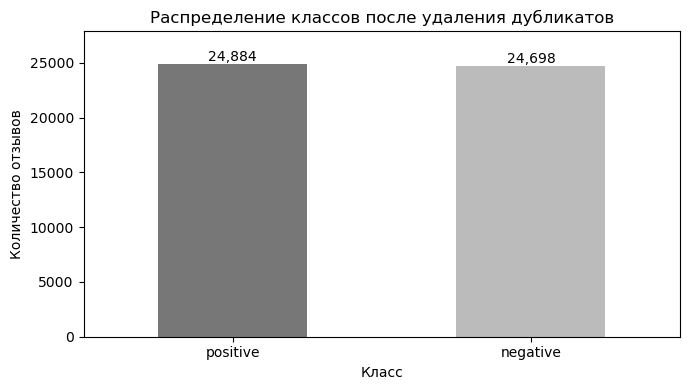

In [8]:
import matplotlib.pyplot as plt

counts = df_clean["sentiment"].value_counts().reindex(
    ["positive", "negative"]
)

ax = counts.plot.bar(
    color=["#777777", "#BBBBBB"],
    figsize=(7, 4),
    rot=0
)

ax.set_title("Распределение классов после удаления дубликатов")
ax.set_xlabel("Класс")
ax.set_ylabel("Количество отзывов")

for i, count in enumerate(counts):
    ax.text(i, count + 300, f"{count:,}", ha="center")

ax.set_ylim(0, counts.max() * 1.12)
plt.tight_layout()
plt.show()

In [9]:
has_html = df_clean["review"].str.contains(r"<[^>]+>", regex=True)

print("Отзывов с HTML-тегами:", has_html.sum())
print(f"Доля отзывов с HTML-тегами: {has_html.mean():.2%}")

Отзывов с HTML-тегами: 28968
Доля отзывов с HTML-тегами: 58.42%


In [10]:
import re
import html

def clean_html(text):
    text = re.sub(r"<[^>]+>", " ", text)
    text = html.unescape(text)
    return re.sub(r"\s+", " ", text).strip()

df_clean["review_clean"] = df_clean["review"].apply(clean_html)

df_clean[["review", "review_clean"]].head(3)

,review,review_clean
0,One of the other reviewers has mentioned that ...,One of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,A wonderful little production. The filming tec...
2,I thought this was a wonderful way to spend ti...,I thought this was a wonderful way to spend ti...


In [11]:
df_clean["char_count"] = df_clean["review_clean"].str.len()
df_clean["word_count"] = df_clean["review_clean"].str.split().str.len()

df_clean[["char_count", "word_count"]].describe().round(2)

,char_count,word_count
count,49582.00,49582.00
mean,1288.02,229.06
std,973.46,169.79
min,32.00,4.00
25%,690.00,125.00
50%,956.00,172.00
75%,1562.00,278.00
max,13593.00,2459.00


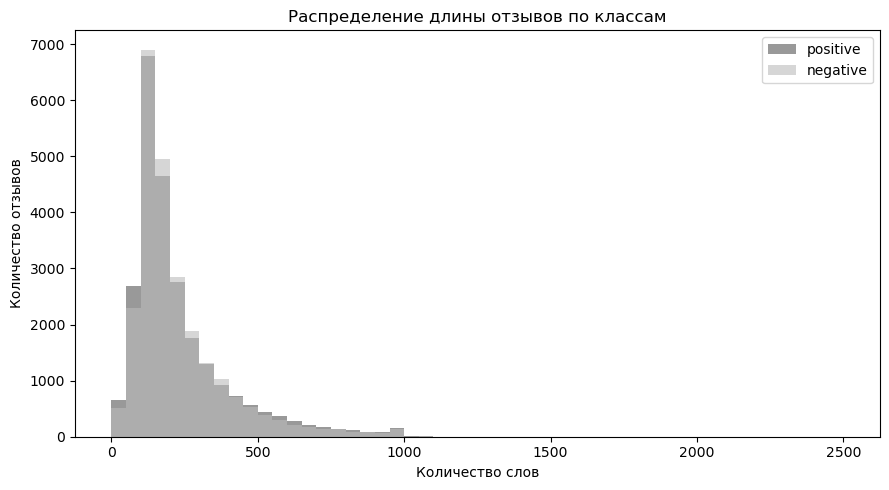

In [12]:
plt.figure(figsize=(9, 5))

for label, color in [("positive", "#555555"), ("negative", "#BBBBBB")]:
    values = df_clean.loc[
        df_clean["sentiment"] == label, "word_count"
    ]
    plt.hist(
        values,
        bins=range(0, 2501, 50),
        alpha=0.6,
        color=color,
        label=label
    )

plt.title("Распределение длины отзывов по классам")
plt.xlabel("Количество слов")
plt.ylabel("Количество отзывов")
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
df_clean.groupby("sentiment")["word_count"].agg(
    count="count",
    mean="mean",
    median="median",
    std="std",
    min="min",
    max="max"
).round(2)

,count,mean,median,std,min,max
sentiment,,,,,,
negative,24698,227.24,173.0,163.33,4,1491
positive,24884,230.86,171.0,175.94,10,2459


In [14]:
print(
    "Повторные тексты после очистки:",
    df_clean.duplicated(subset=["review_clean"]).sum()
)

labels_per_clean_review = (
    df_clean.groupby("review_clean")["sentiment"].nunique()
)

print(
    "Очищенные тексты с разными метками:",
    (labels_per_clean_review > 1).sum()
)

print(
    "Пустые тексты после очистки:",
    df_clean["review_clean"].eq("").sum()
)

Повторные тексты после очистки: 4
Очищенные тексты с разными метками: 0
Пустые тексты после очистки: 0


In [15]:
df_clean = (
    df_clean.drop_duplicates(subset=["review_clean"])
    .copy()
)

print("Итоговое количество отзывов:", len(df_clean))
print("\nКоличество отзывов по классам:")
print(df_clean["sentiment"].value_counts())

Итоговое количество отзывов: 49578

Количество отзывов по классам:
sentiment
positive    24882
negative    24696
Name: count, dtype: int64


In [17]:
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_words = set(ENGLISH_STOP_WORDS) - {"no", "not", "nor", "never"}

def get_word_counts(texts):
    counts = Counter()

    for text in texts:
        words = re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())
        counts.update(
            word for word in words
            if word not in stop_words and len(word) > 1
        )

    return counts

word_counts = {
    label: get_word_counts(
        df_clean.loc[df_clean["sentiment"] == label, "review_clean"]
    )
    for label in ["positive", "negative"]
}

print("Частоты слов рассчитаны для обоих классов.")

Частоты слов рассчитаны для обоих классов.


In [18]:
top_words = pd.concat(
    {
        label: pd.DataFrame(
            word_counts[label].most_common(20),
            columns=["Слово", "Число употреблений"]
        )
        for label in ["positive", "negative"]
    },
    axis=1
)

display(top_words)

positive                       negative                   
         Слово Число употреблений       Слово Число употреблений
0         film              40887       movie              49170
1        movie              37300        film              36318
2          not              28202         not              32064
3         like              17650        like              22191
4         it's              16692        just              20869
5         good              14963        it's              16599
6         just              14057          no              15889
7        great              12888        good              14572
8        story              12833         bad              14562
9         time              12693      really              12216
10      really              10707        time              12196
11          no               9198       don't              10103
12        love               8649       story              10031
13      people               8519        make               9261
14        best               8477      people               9184
15        life               8026      movies               8245
16         way               7832        plot               8111
17       films               7578      acting               7994
18       think               7172         way               7682
19  characters               7070  characters               7246

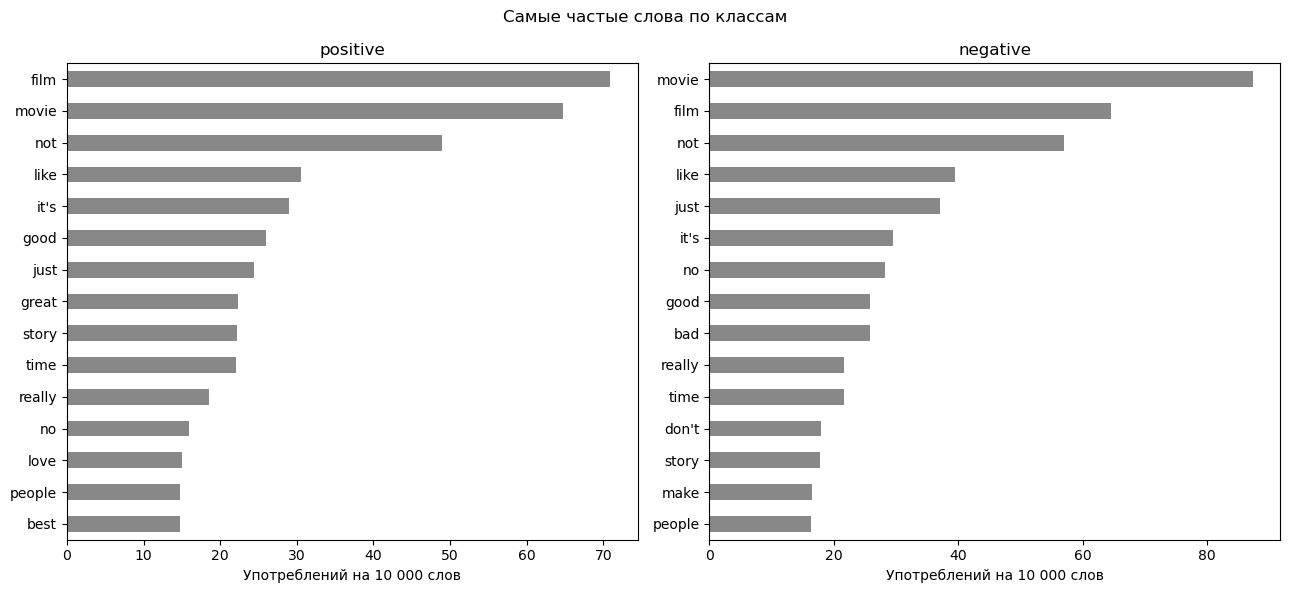

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, label in zip(axes, ["positive", "negative"]):
    top = pd.Series(dict(word_counts[label].most_common(15)))
    total_words = df_clean.loc[
        df_clean["sentiment"] == label, "review_clean"
    ].apply(
        lambda text: len(
            re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())
        )
    ).sum()

    frequencies = top / total_words * 10000

    frequencies.sort_values().plot.barh(
        ax=ax,
        color="#888888"
    )

    ax.set_title(label)
    ax.set_xlabel("Употреблений на 10 000 слов")
    ax.set_ylabel("")

fig.suptitle("Самые частые слова по классам")
plt.tight_layout()
plt.show()

In [21]:
summary = df_clean.groupby("sentiment").agg(
    reviews=("review_clean", "size"),
    mean_words=("word_count", "mean"),
    median_words=("word_count", "median"),
    min_words=("word_count", "min"),
    max_words=("word_count", "max")
)

summary["share_percent"] = (
    summary["reviews"] / len(df_clean) * 100
)

display(summary.round(2))

,reviews,mean_words,median_words,min_words,max_words,share_percent
sentiment,,,,,,
negative,24696,227.25,173.0,4,1491,49.81
positive,24882,230.87,171.0,10,2459,50.19


### Выводы по исследовательскому анализу данных

Исходный датасет содержит 50 000 англоязычных отзывов и два столбца:
review — текст отзыва, sentiment — метка тональности.
Пропущенных значений и пустых строк не обнаружено.

Исходные классы сбалансированы: по 25 000 положительных и
отрицательных отзывов.

Обнаружено и удалено 418 точных дубликатов. В 28 968 оставшихся
отзывах (58,42%) найдены фрагменты, соответствующие шаблону HTML-тегов.
После удаления тегов, декодирования HTML-сущностей и нормализации
пробелов обнаружены ещё 4 повторные записи. Противоречивых меток
у одинаковых текстов не выявлено.

Итоговый набор содержит 49 578 отзывов:
- positive — 24 882 (50,19%);
- negative — 24 696 (49,81%).

Распределение длины отзывов имеет длинный правый хвост.
Средняя длина положительных отзывов составляет 230,87 слова,
отрицательных — 227,25 слова. Медианы равны 171 и 173 словам
соответственно. Центральные характеристики длины близки,
поэтому явного разделения классов по длине не наблюдается.
Длинные отзывы сохранены: сама по себе большая длина не
свидетельствует об ошибке данных.

Среди частых слов обоих классов преобладают тематические слова
film и movie. В положительных отзывах в число частых входят
great, love и best, в отрицательных — bad. Слово good встречается
в обоих классах, что подчёркивает необходимость учитывать контекст
и отрицания. Частотный анализ является описательным и сам по себе
не подтверждает предсказательную силу слов.

Перед обучением необходимо зафиксировать разбиения данных.
Ручное и синтетическое обогащение следует выполнять только
для обучающей части каждого разбиения. Тестовые данные должны
оставаться одинаковыми при сравнении четырёх вариантов обучения.